# Docs figures: USTAR threshold constraints (L3.3)

**notebook version**: `1` (6 Nov 2026)

## ℹ️ About this notebook

Draws the three figures of the documentation page *Threshold constraints* (`docs/L3.3_Constraints.md`)
and writes them to `docs/images/`:

| Figure on the page | File |
|---|---|
| `@fig-c33-nee-ta`: night-time `NEE` against `USTAR` per air temperature class | `USTAR_night_NEE_by_TA_class.png` |
| `@fig-c33-methods`: thresholds of each method and record | `USTAR_thresholds_by_method.png` |
| `@fig-c33-reco-dt`: night-time `NEE` over `RECO_DT` against `USTAR` | `USTAR_night_NEE_vs_RECO_DT.png` |

The figures are drawn from the tables that
`30_FLUX_POST-PROCESSING_CHAIN/USTAR_THRESHOLD_DETECTION_2004-2026.09` shows in its committed outputs,
so this notebook needs neither the external data folder nor a rerun of the detection notebook. Run it
after the detection notebook. The thresholds of FP2026.1 and FP2026.2 are declared under *Settings*, as
in the detection notebook, and checked against the table of that notebook.

Each figure is saved as the page shows it; the caption below it in this notebook is added afterwards
and is not part of the file.

## ⚙️ Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # the repository root, two levels above this notebook
NB = ROOT / 'workflow' / '30_FLUX_POST-PROCESSING_CHAIN' / 'USTAR_THRESHOLD_DETECTION_2004-2026.09.ipynb'
OUT = ROOT / 'docs' / 'images'

# Thresholds (m s-1), as declared in the detection notebook (USTAR_THRESHOLDS, USTAR_THRESHOLDS_FP1)
FP2 = {'LI-7200': [0.4155, 0.5264, 0.6472], 'LI-7500': [0.3182, 0.4350, 0.5459]}
FP1 = [0.2716, 0.3036, 0.3397]

# Ids of the markdown cells above the tables read from the detection notebook
CELL_NEE_BY_TA = 'ustd-curve_tab_md'
CELL_RATIO_RECO_DT = '49b947af'
CELL_THRESHOLDS = 'ustd-det_cut_md'
CELL_FLUXNET = 'ustd-flx_thr_md'

INK, MUTED, GRID = '#1F2623', '#5A6460', '#E4E7E4'
TA_COLORS = ['#F2C18A', '#E59A55', '#C96F2B', '#9C4A16', '#66290A']  # one hue, light to dark
SEASON_COLORS = {'May-Oct': '#B5561A', 'Nov-Apr': '#2B6CA3'}
BAND = '#2E6A4E'

In [2]:
from datetime import datetime
import html
import json
import re
import textwrap

import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 10, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 150, 'figure.dpi': 100})

def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


def save_for_docs(fig, name):
    """Write the figure as the docs page shows it, before the notebook caption is added."""
    path = OUT / name
    fig.savefig(path)
    print(f"written: {path.relative_to(ROOT)}")
    return path


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-06 16:04:23


## 📂 Load the detection notebook

In [3]:
nb = json.loads(NB.read_text(encoding='utf-8'))
print(f"{NB.name}: {len(nb['cells'])} cells")


def table_after(nb, heading_id):
    """Rows of the first HTML table in the outputs of the cell after the markdown cell `heading_id`."""
    ids = [c.get('id') for c in nb['cells']]
    cell = nb['cells'][ids.index(heading_id) + 1]
    for o in cell.get('outputs', []):
        h = o.get('data', {}).get('text/html')
        if h:
            rows = re.findall(r'<tr>(.*?)</tr>', ''.join(h), re.S)
            return [[html.unescape(re.sub('<.*?>', '', x)).strip()
                     for x in re.findall(r'<t[hd][^>]*>(.*?)</t[hd]>', r, re.S)] for r in rows]
    raise ValueError(f'no table after {heading_id}')


def mid(label):
    """Midpoint of a bin label such as '0.3-0.4'."""
    lo, hi = (float(v) for v in label.split('-'))
    return (lo + hi) / 2


def thresholds(ax, fp2, ymax_label=True):
    """Mark CUT_16 to CUT_84 and CUT_50 of FP2026.2, and CUT_50 of FP2026.1."""
    ax.axvspan(fp2[0], fp2[2], color=BAND, alpha=0.12, lw=0)
    ax.axvline(fp2[1], color=BAND, lw=1.5)
    ax.axvline(FP1[1], color=MUTED, lw=1.2, ls='--')
    if ymax_label:
        y = ax.get_ylim()[1]
        ax.text(fp2[1] + 0.01, y, 'FP2026.2\nCUT_50', va='top', ha='left', fontsize=8.5, color=BAND)
        ax.text(FP1[1] - 0.01, y, 'FP2026.1\nCUT_50', va='top', ha='right', fontsize=8.5, color=MUTED)

USTAR_THRESHOLD_DETECTION_2004-2026.09.ipynb: 142 cells


## 🔍 Check the declared thresholds

In [4]:
# The detection notebook detects the thresholds of each analyser on its own record and checks the
# declared values against them to 0.005 m s-1. Its table shows them rounded to 0.01 m s-1, so here the
# declared values must lie within half a unit of that rounding.
_det = {}
_record = None
for r in table_after(nb, CELL_THRESHOLDS)[2:]:
    if len(r) == 6:
        _record, r = r[0], r[1:]
    _det[(_record, r[0])] = [float(v) for v in r[1:4]]
for _name, _declared in FP2.items():
    _detected = _det[(_name, 'oneflux_mp')]
    _diff = max(abs(a - b) for a, b in zip(_declared, _detected))
    print(f"{_name}: declared {_declared}, detected {_detected}, largest difference {_diff:.4f} m s-1")
    assert _diff <= 0.0051, f"{_name}: the declared thresholds differ from the detection notebook"

LI-7200: declared [0.4155, 0.5264, 0.6472], detected [0.42, 0.53, 0.65], largest difference 0.0045 m s-1
LI-7500: declared [0.3182, 0.435, 0.5459], detected [0.32, 0.43, 0.55], largest difference 0.0050 m s-1


## Night-time NEE against USTAR per air temperature class

### 📊 Plot: mean night-time NEE against USTAR, per air temperature class and analyser

written: docs\images\USTAR_night_NEE_by_TA_class.png


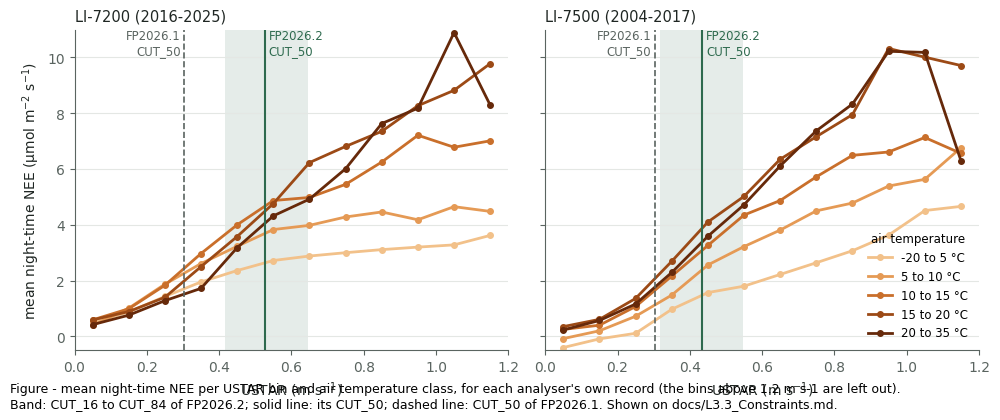

In [5]:
rows = table_after(nb, CELL_NEE_BY_TA)
header, body = rows[0], [r for r in rows[2:] if r[0] != '1.2-3.0']
x = [mid(r[0]) for r in body]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, (name, first) in zip(axes, [('LI-7200 (2016-2025)', 1), ('LI-7500 (2004-2017)', 7)]):
    for k in range(5):
        col = first + k
        label = header[col].split(', TA ')[1]
        ax.plot(x, [float(r[col]) for r in body], color=TA_COLORS[k], lw=2, marker='o', ms=4, label=label)
    ax.set_title(name, loc='left', fontsize=10.5, color=INK)
    ax.set_xlabel('USTAR (m s$^{-1}$)')
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_xlim(0, 1.2)
    ax.set_ylim(-0.5, 11)
    thresholds(ax, FP2[name.split(' ')[0]])
axes[0].set_ylabel('mean night-time NEE (µmol m$^{-2}$ s$^{-1}$)')
axes[1].legend(title='air temperature', frameon=False, loc='lower right', fontsize=8.5, title_fontsize=8.5)
fig.tight_layout()
save_for_docs(fig, 'USTAR_night_NEE_by_TA_class.png')
figcap(fig, "mean night-time NEE per USTAR bin and air temperature class, for each analyser's own record "
            "(the bins above 1.2 m s-1 are left out). Band: CUT_16 to CUT_84 of FP2026.2; solid line: its CUT_50; "
            "dashed line: CUT_50 of FP2026.1. Shown on docs/L3.3_Constraints.md.")
plt.show()

## Thresholds of each method and record

### 📊 Plot: USTAR thresholds of each detection method, record and FLUXNET

written: docs\images\USTAR_thresholds_by_method.png


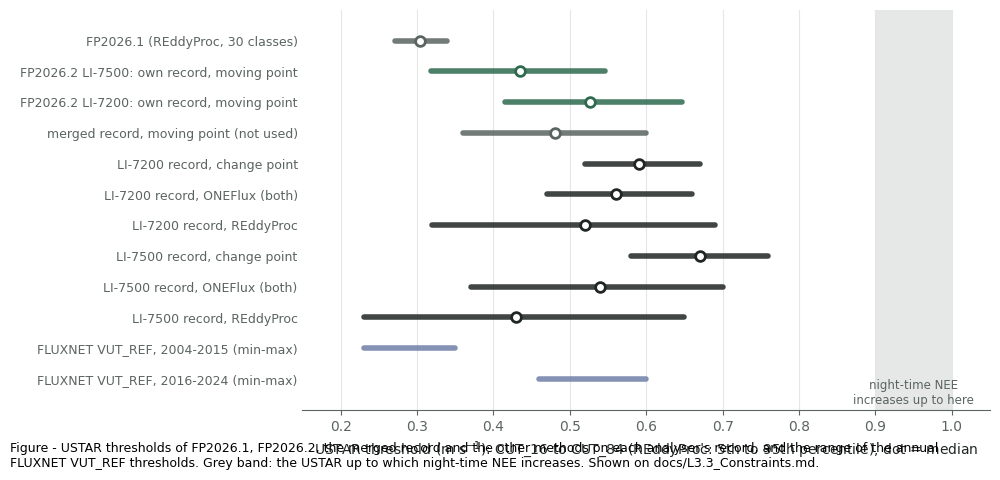

In [6]:
flx = table_after(nb, CELL_FLUXNET)[2:]
vut = {int(r[0]): float(r[1]) for r in flx}
names = {'oneflux_mp': 'moving point', 'oneflux_cp': 'change point', 'oneflux': 'ONEFlux (both)',
         'reddyproc': 'REddyProc'}
items = [('FP2026.1 (REddyProc, 30 classes)', FP1, MUTED),
         ('FP2026.2 LI-7500: own record, moving point', FP2['LI-7500'], BAND),
         ('FP2026.2 LI-7200: own record, moving point', FP2['LI-7200'], BAND),
         ('merged record, moving point (not used)', _det[('merged record', 'oneflux_mp')], MUTED)]
for rec in ['LI-7200', 'LI-7500']:
    for m in ['oneflux_cp', 'oneflux', 'reddyproc']:
        items.append((f'{rec} record, {names[m]}', _det[(rec, m)], INK))
lo7500 = [v for y, v in vut.items() if y <= 2015]
lo7200 = [v for y, v in vut.items() if y >= 2016]
items.append(('FLUXNET VUT_REF, 2004-2015 (min-max)', [min(lo7500), None, max(lo7500)], '#6F7FA6'))
items.append(('FLUXNET VUT_REF, 2016-2024 (min-max)', [min(lo7200), None, max(lo7200)], '#6F7FA6'))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(0.9, 1.0, color=MUTED, alpha=0.15, lw=0)
ax.text(0.95, -0.9, 'night-time NEE\nincreases up to here', ha='center', va='bottom', fontsize=8.5, color=MUTED)
for i, (label, (lo, med, hi), color) in enumerate(items):
    y = len(items) - 1 - i
    ax.plot([lo, hi], [y, y], color=color, lw=4, solid_capstyle='round', alpha=0.85)
    if med is not None:
        ax.plot(med, y, 'o', color='white', ms=7, mec=color, mew=2)
ax.set_yticks(range(len(items)))
ax.set_yticklabels([it[0] for it in reversed(items)], fontsize=9)
ax.set_xlim(0.15, 1.05)
ax.set_ylim(-1, len(items))
ax.set_xlabel('USTAR threshold (m s$^{-1}$): CUT_16 to CUT_84 (REddyProc: 5th to 95th percentile), dot = median')
ax.grid(axis='x', color=GRID, lw=0.8)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)
fig.tight_layout()
save_for_docs(fig, 'USTAR_thresholds_by_method.png')
figcap(fig, "USTAR thresholds of FP2026.1, FP2026.2, the merged record and the other methods on each "
            "analyser's record, and the range of the annual FLUXNET VUT_REF thresholds. Grey band: the USTAR up "
            "to which night-time NEE increases. Shown on docs/L3.3_Constraints.md.")
plt.show()

## Night-time NEE against the daytime respiration

### 📊 Plot: night-time NEE over RECO_DT against USTAR, per season and analyser

written: docs\images\USTAR_night_NEE_vs_RECO_DT.png


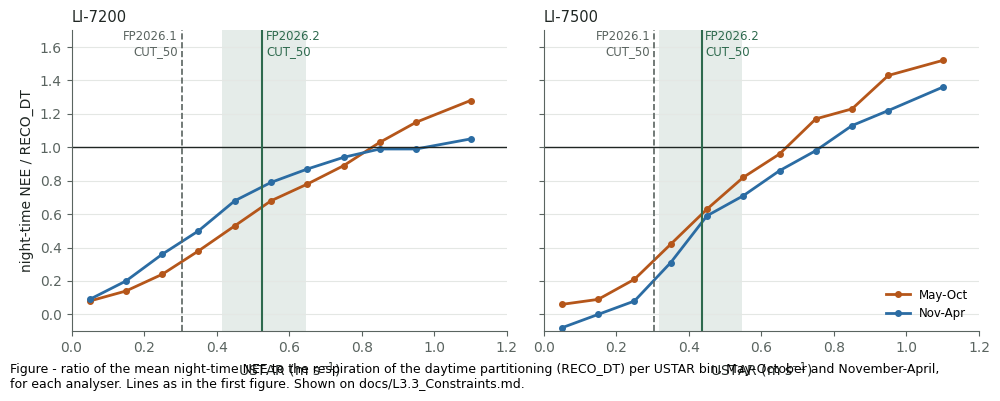

In [7]:
rows = table_after(nb, CELL_RATIO_RECO_DT)
data, analyser, season = {}, None, None
for r in rows[1:]:
    if len(r) == 7:
        analyser, season = r[0], r[1]
    elif len(r) == 6:
        season = r[0]
    bin_label, ratio = r[-5], r[-1]
    if bin_label == '1.2-3.0':
        continue
    data.setdefault((analyser, season), []).append((mid(bin_label), float(ratio)))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, name in zip(axes, ['LI-7200', 'LI-7500']):
    for season, color in SEASON_COLORS.items():
        pts = data[(name, season)]
        ax.plot([p[0] for p in pts], [p[1] for p in pts], color=color, lw=2, marker='o', ms=4, label=season)
    ax.axhline(1, color=INK, lw=1)
    ax.set_title(name, loc='left', fontsize=10.5, color=INK)
    ax.set_xlabel('USTAR (m s$^{-1}$)')
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_xlim(0, 1.2)
    ax.set_ylim(-0.1, 1.7)
    thresholds(ax, FP2[name])
axes[0].set_ylabel('night-time NEE / RECO_DT')
axes[1].legend(frameon=False, loc='lower right', fontsize=8.5)
fig.tight_layout()
save_for_docs(fig, 'USTAR_night_NEE_vs_RECO_DT.png')
figcap(fig, "ratio of the mean night-time NEE to the respiration of the daytime partitioning (RECO_DT) per "
            "USTAR bin, May-October and November-April, for each analyser. Lines as in the first figure. "
            "Shown on docs/L3.3_Constraints.md.")
plt.show()

## ⏱️ Runtime

In [8]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, "
      f"runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-06 16:04:24, runtime 0:00:01.187865
